# HOUSE PRICE PREDICTION USING MACHINE LEARNING
# Algorithm: Linear Regression

# Project Problem

### A real estate company wants to estimate the selling price of houses based on their characteristics. As a data scientist, your task is to explore the house data and build a machine learning model that can predict the price of a house.

In [11]:
# pandas is used for working with tables and datasets
import pandas as pd

# numpy is used for numerical calculations
import numpy as np

# matplotlib is used for creating charts and graphs
import matplotlib.pyplot as plt

# seaborn is used for creating attractive statistical charts
import seaborn as sns

# LinearRegression is the machine learning algorithm
# we will use to predict house prices
from sklearn.linear_model import LinearRegression

# train_test_split helps us divide our data into
# training data and testing data
from sklearn.model_selection import train_test_split

# These metrics will help us evaluate how well our model performs
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [13]:
House = pd.read_csv("house_price_prediction.csv")

In [17]:
House.head()

,House_ID,Location,Bedrooms,Bathrooms,Size_sqft,House_Age,Parking_Spaces,Price_NGN
0,H0001,Lagos,2,2,2233,22,4,110900000
1,H0002,Kano,3,3,1989,12,2,63490000
2,H0003,Ibadan,4,4,2026,22,4,77450000
3,H0004,Port Harcourt,4,4,899,17,3,56860000
4,H0005,Abuja,4,4,2317,27,1,103770000


In [30]:
# shape returns:
# number of rows and number of columns
House.shape

(1000, 8)

In [32]:
# Display all column names in the dataset
House.columns

Index(['House_ID', 'Location', 'Bedrooms', 'Bathrooms', 'Size_sqft',
       'House_Age', 'Parking_Spaces', 'Price_NGN'],
      dtype='object')

In [34]:
# describe() gives statistical information
# such as count, mean, minimum, maximum and quartiles
House.describe()

,Bedrooms,Bathrooms,Size_sqft,House_Age,Parking_Spaces,Price_NGN
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1.000000e+03
mean,2.969000,2.933000,1654.351000,15.48600,1.992000,7.579800e+07
std,1.054111,1.123287,545.067499,8.82472,0.951231,2.309766e+07
min,1.000000,1.000000,500.000000,0.00000,0.000000,1.780000e+07
25%,2.000000,2.000000,1258.000000,8.00000,1.000000,5.906000e+07
50%,3.000000,3.000000,1652.000000,16.00000,2.000000,7.417500e+07
75%,4.000000,4.000000,2026.250000,23.00000,3.000000,9.280500e+07
max,5.000000,6.000000,3809.000000,30.00000,4.000000,1.744700e+08


In [36]:
# isnull() checks for missing values
# sum() counts the missing values in each column
House.isnull().sum()

House_ID          0
Location          0
Bedrooms          0
Bathrooms         0
Size_sqft         0
House_Age         0
Parking_Spaces    0
Price_NGN         0
dtype: int64

In [38]:
# duplicated() identifies duplicate rows
# sum() tells us how many duplicate rows exist
House.duplicated().sum()

np.int64(0)

In [40]:
# unique() displays the different values
# available in the Location column
House["Location"].unique()

array(['Lagos', 'Kano', 'Ibadan', 'Port Harcourt', 'Abuja'], dtype=object)

In [42]:
# value_counts() counts the number of houses
# in each location
House["Location"].value_counts()

Location
Lagos            287
Abuja            238
Port Harcourt    170
Kano             153
Ibadan           152
Name: count, dtype: int64

# EXPLORATORY DATA ANALYSIS (EDA)
## 1 DISTRIBUTION OF HOUSE PRICES

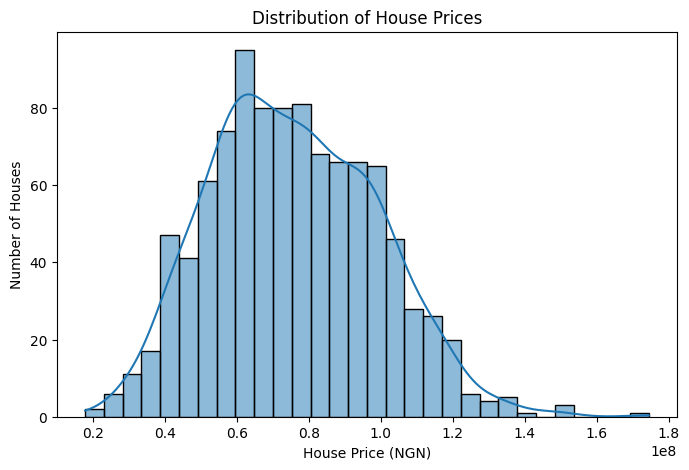

In [49]:
# Create a histogram showing the distribution of house prices
plt.figure(figsize=(8, 5))

sns.histplot(House["Price_NGN"], bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price (NGN)")
plt.ylabel("Number of Houses")

plt.show()

## 2HOUSE SIZE VS HOUSE PRICE

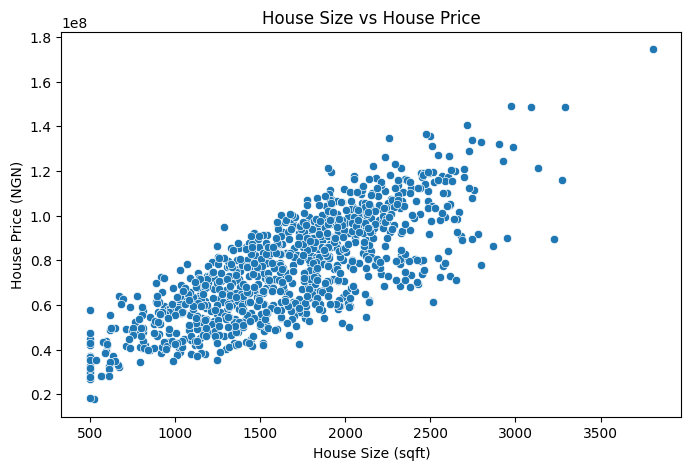

In [52]:
# Create a scatter plot showing the relationship
# between house size and house price
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=House,
    x="Size_sqft",
    y="Price_NGN"
)

plt.title("House Size vs House Price")
plt.xlabel("House Size (sqft)")
plt.ylabel("House Price (NGN)")

plt.show()

## 3 NUMBER OF BEDROOMS VS HOUSE PRICE

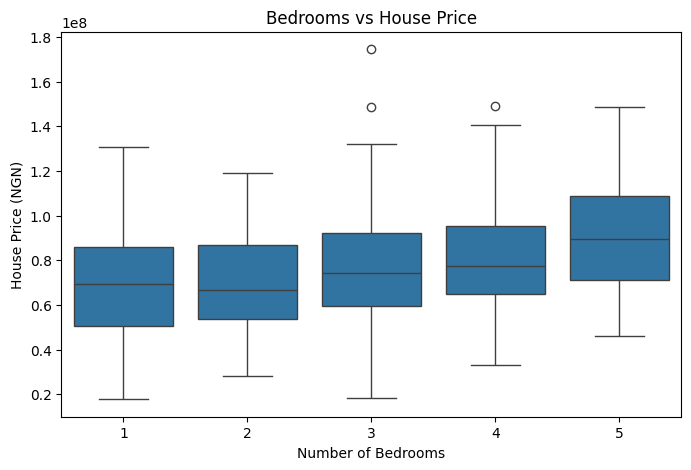

In [55]:
# Boxplot helps us compare house prices
# across different numbers of bedrooms
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=House,
    x="Bedrooms",
    y="Price_NGN"
)

plt.title("Bedrooms vs House Price")
plt.xlabel("Number of Bedrooms")
plt.ylabel("House Price (NGN)")

plt.show()

## 4 HOUSE AGE VS HOUSE PRICE

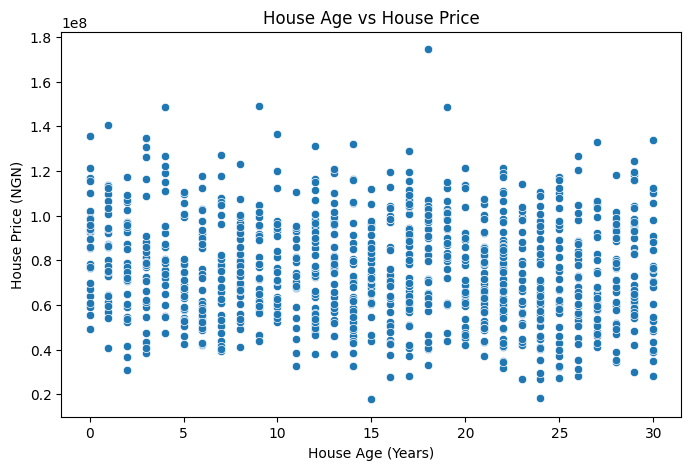

In [58]:
# Scatter plot showing whether house age
# has a relationship with price
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=House,
    x="House_Age",
    y="Price_NGN"
)

plt.title("House Age vs House Price")
plt.xlabel("House Age (Years)")
plt.ylabel("House Price (NGN)")

plt.show()

## 5 HOUSE PRICE BY LOCATION

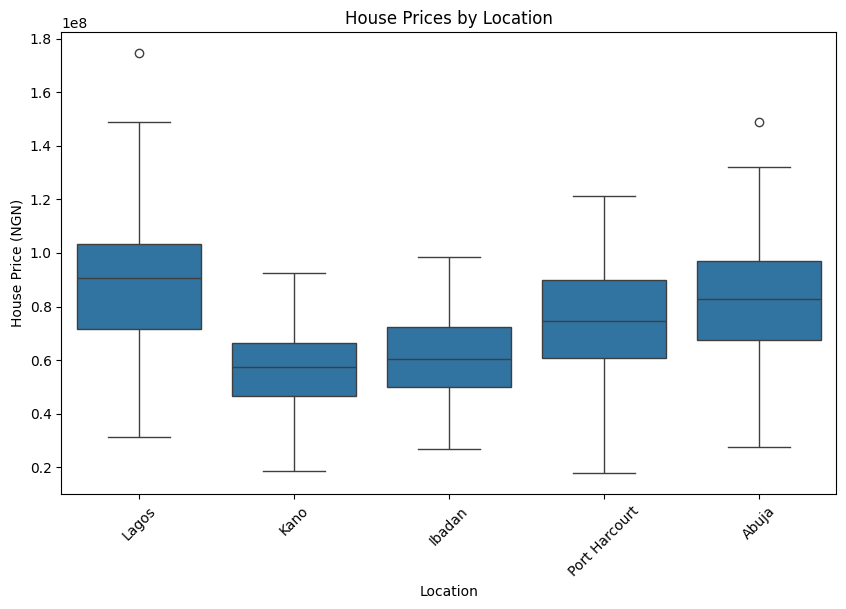

In [61]:
# Boxplot allows us to compare house prices
# across different locations
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=House,
    x="Location",
    y="Price_NGN"
)

plt.title("House Prices by Location")
plt.xlabel("Location")
plt.ylabel("House Price (NGN)")

plt.xticks(rotation=45)

plt.show()

# CORRELATION ANALYSIS

In [64]:
# Select only numerical columns
numeric_columns = House.select_dtypes(include="number")

# Calculate the correlation between numerical variables
correlation = numeric_columns.corr()

# Display the correlation table
correlation

,Bedrooms,Bathrooms,Size_sqft,House_Age,Parking_Spaces,Price_NGN
Bedrooms,1.000000,0.922256,-0.019746,-0.004835,-0.008234,0.224144
Bathrooms,0.922256,1.000000,-0.000759,-0.007416,0.000435,0.231689
Size_sqft,-0.019746,-0.000759,1.000000,0.022786,0.038867,0.788325
House_Age,-0.004835,-0.007416,0.022786,1.000000,-0.009076,-0.099465
Parking_Spaces,-0.008234,0.000435,0.038867,-0.009076,1.000000,0.100505
Price_NGN,0.224144,0.231689,0.788325,-0.099465,0.100505,1.000000


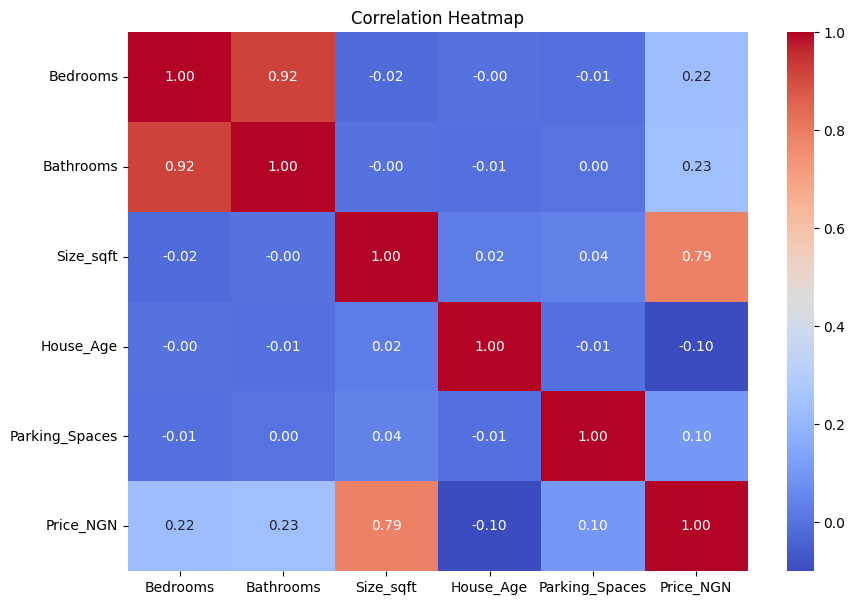

In [66]:
# Create the figure
plt.figure(figsize=(10, 7))

# Create a heatmap from the correlation table
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

# PREPARE THE DATA FOR MACHINE LEARNING

In [69]:
# We want the model to predict Price_NGN.
# Therefore, Price_NGN is our TARGET variable.

# X contains the FEATURES we use to make predictions.
# We will use:
# Bedrooms
# Bathrooms
# Size_sqft
# House_Age
# Parking_Spaces

X = House[
    [
        "Bedrooms",
        "Bathrooms",
        "Size_sqft",
        "House_Age",
        "Parking_Spaces"
    ]
]


# y contains the TARGET we want the model to predict
y = House["Price_NGN"]

# CHECK X AND y

In [72]:
# Display the first 5 rows of our features
X.head()


# Display the first 5 target values
y.head()

0    110900000
1     63490000
2     77450000
3     56860000
4    103770000
Name: Price_NGN, dtype: int64

# SPLIT THE DATA

In [75]:
# We divide the dataset into:
# 80% training data
# 20% testing data

# random_state=42 ensures we get the same split
# every time we run the code

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# CHECK THE TRAINING AND TESTING DATA

In [78]:
# Number of rows in training features
X_train.shape


# Number of rows in testing features
X_test.shape


# Number of rows in training target
y_train.shape


# Number of rows in testing target
y_test.shape

(200,)

# CREATE THE MACHINE LEARNING MODEL

In [81]:
# Create a Linear Regression model
model = LinearRegression()

In [83]:
# TRAIN THE MODEL

In [85]:
# fit() teaches the model the relationship
# between our features and house prices
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


# MAKE PREDICTIONS

In [88]:
# Use the trained model to predict prices
# for houses in the testing dataset
y_pred = model.predict(X_test)


# Display the first 10 predictions
y_pred[:10]

array([1.03785119e+08, 9.67410528e+07, 4.50804405e+07, 7.18754580e+07,
       5.96624529e+07, 6.46275049e+07, 8.73225611e+07, 7.79844472e+07,
       9.21396448e+07, 7.31458002e+07])

# COMPARE ACTUAL AND PREDICTED PRICES

In [91]:
# Create a new DataFrame containing:
# Actual price
# Predicted price

comparison = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred
})

# Display the first 10 comparisons
comparison.head(10)

,Actual_Price,Predicted_Price
0,121430000,1.037851e+08
1,80610000,9.674105e+07
2,49850000,4.508044e+07
3,87730000,7.187546e+07
4,47640000,5.966245e+07
5,42720000,6.462750e+07
6,104420000,8.732256e+07
7,59170000,7.798445e+07
8,96100000,9.213964e+07
9,80200000,7.314580e+07


#  EVALUATE THE MODEL

In [94]:
# MAE tells us the average amount by which
# our predictions are wrong
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 9859525.862972679


In [96]:
# MSE calculates the average squared difference
# between actual and predicted values
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 143472786469123.62


In [98]:
# RMSE is the square root of MSE.
# It puts the error back into the same unit
# as the house price.
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 11978012.626021214


In [100]:
# R2 tells us how well the features explain
# the variation in house prices.
# A value closer to 1 generally means
# the model explains the data better.

r2 = r2_score(y_test, y_pred)

print("R-squared:", r2)

R-squared: 0.744918276106159


# DISPLAY THE RESULTS NEATLY

In [103]:
print("MODEL EVALUATION")
print("-------------------------")

print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

MODEL EVALUATION
-------------------------
MAE : 9859525.86
MSE : 143472786469123.62
RMSE: 11978012.63
R²  : 0.7449


# VISUALIZE ACTUAL VS PREDICTED PRICES

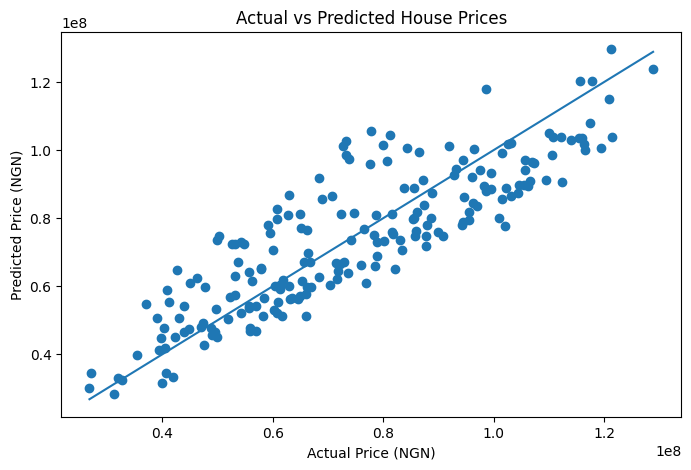

In [106]:
plt.figure(figsize=(8, 5))

# Scatter plot of actual prices against predicted prices
plt.scatter(y_test, y_pred)

# Add a line representing perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price (NGN)")
plt.ylabel("Predicted Price (NGN)")

plt.show()

# LOOK AT THE MODEL COEFFICIENTS

In [109]:
# Linear Regression gives each feature a coefficient.
# The coefficient shows how the feature affects
# the predicted house price while other features
# are held constant.

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients

,Feature,Coefficient
0,Bedrooms,2.983831e+06
1,Bathrooms,2.152937e+06
2,Size_sqft,3.364782e+04
3,House_Age,-3.377813e+05
4,Parking_Spaces,2.004823e+06


In [111]:
# The intercept is the predicted value when
# all features are zero.
model.intercept_

np.float64(6083823.447499171)

In [113]:
# Let's create information for a new house.

new_house = pd.DataFrame({
    "Bedrooms": [3],
    "Bathrooms": [2],
    "Size_sqft": [1800],
    "House_Age": [5],
    "Parking_Spaces": [2]
})


# Use our trained model to predict the price
new_prediction = model.predict(new_house)


# Display the predicted price
print("Predicted House Price: ₦", round(new_prediction[0], 2))

Predicted House Price: ₦ 82228015.06
